### Verify GPU and set up reproducibility



In [1]:
!nvidia-smi

Sat Sep 26 10:10:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install -q ultralytics

import random, os
import numpy as np
import torch
import ultralytics

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print('Ultralytics version:', ultralytics.__version__)
print('Torch version:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
print('Seed fixed to:', SEED)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.0/91.0 kB 10.5 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.163
Torch version: 2.11.0+cu128
CUDA available: True
Seed fixed to: 42


### Load your dataset

In [4]:
import os, glob, shutil, zipfile

from google.colab import drive
drive.mount('/content/gdrive', force_remount=False)

# Edit this if your files live somewhere else in Drive
SEARCH_DIRS = [
    '/content/gdrive/MyDrive/Advanced ML 2026/Assignment 1 final',
    '/content/gdrive/MyDrive',
]

def find_zip(folders, want_test):
    for d in folders:
        if not os.path.isdir(d):
            continue
        for f in sorted(glob.glob(os.path.join(d, '*.zip'))):
            has_test = 'test' in os.path.basename(f).lower()
            if has_test == want_test:
                return f
    return None

data_src = find_zip(SEARCH_DIRS, want_test=False)
test_src = find_zip(SEARCH_DIRS, want_test=True)

if data_src and test_src:
    print('Found in Drive:')
    print('  data ->', data_src)
    print('  test ->', test_src)
else:
    print('Could not auto-locate both zips under', SEARCH_DIRS[0])
    print('Falling back to a manual upload picker (one file per prompt).')
    from google.colab import files
    if not data_src:
        print('Upload your labelled dataset zip:')
        data_src = list(files.upload().keys())[0]
    if not test_src:
        print('Upload your unlabeled test zip:')
        test_src = list(files.upload().keys())[0]

shutil.copy(data_src, '/content/data_zip.zip')
shutil.copy(test_src, '/content/test.zip')

def safe_unzip(zip_path, dest):
    os.makedirs(dest, exist_ok=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(dest)
    # Guard against an accidental double-zip (a .zip nested inside the .zip)
    if not os.path.isdir(os.path.join(dest, 'images')):
        inner_zips = glob.glob(os.path.join(dest, '*.zip')) + \
                     glob.glob(os.path.join(dest, '**', '*.zip'), recursive=True)
        if inner_zips:
            print(f'  note: {os.path.basename(zip_path)} contained a nested zip '
                  f'- extracting {os.path.basename(inner_zips[0])} too')
            with zipfile.ZipFile(inner_zips[0]) as z:
                z.extractall(dest)

safe_unzip('/content/data_zip.zip', '/content/full_dataset')
safe_unzip('/content/test.zip', '/content/unseen_demo')

print('Labelled images:', len(os.listdir('/content/full_dataset/images')))
print('Labelled label files:', len(os.listdir('/content/full_dataset/labels')))

# test.zip may extract with or without its original 'test/' subfolder
test_dir = '/content/unseen_demo/test' if os.path.isdir('/content/unseen_demo/test') else '/content/unseen_demo'
n_test_imgs = len([f for f in os.listdir(test_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
print('Unlabeled demo images:', n_test_imgs)

with open('/content/full_dataset/classes.txt') as f:
    print('Classes:', [c.strip() for c in f if c.strip()])


Mounted at /content/gdrive
Found in Drive:
  data -> /content/gdrive/MyDrive/Advanced ML 2026/Assignment 1 final/data.zip.zip
  test -> /content/gdrive/MyDrive/Advanced ML 2026/Assignment 1 final/test.zip
Labelled images: 177
Labelled label files: 177
Unlabeled demo images: 18
Classes: ['cloth', 'glove', 'helmet']


### 2. Task 1 - Train / Validation / Test split

In [5]:
import re, shutil, collections, yaml

IMG_DIR = '/content/full_dataset/images'
LBL_DIR = '/content/full_dataset/labels'
CLASSES = ['cloth', 'glove', 'helmet']  # order must match classes.txt / notes.json
OUT_ROOT = '/content/data'

# Maps each source-video clip to a split. Whole clips move together -> no leakage.
SPLIT_MAP = {
    '1_coat_0002': 'train', '1_helmet_coat_glove_0001': 'train', '1_coat_0001_3': 'train',
    '1_helmet_coat_0003': 'train', '1_helmet_0002': 'train', '3_helmet_coat_0001': 'train',
    '1_helmet_coat_0004': 'train',
    '1_helmet_coat_glove_0003': 'val', '1_helmet_glove_0002': 'val', '1_helmet_0003': 'val',
    '3_helmet_glove_0001': 'test', '1_helmet_coat_glove_0002': 'test',
    '3_coat_0001': 'test', '3_glove_0001': 'test',
}

CLIP_RE = re.compile(r'^[0-9a-f]{8}-(.+?)_mp4-(\d+)_jpg')

if os.path.exists(OUT_ROOT):
    shutil.rmtree(OUT_ROOT)
for split in ['train', 'val', 'test']:
    os.makedirs(f'{OUT_ROOT}/{split}/images', exist_ok=True)
    os.makedirs(f'{OUT_ROOT}/{split}/labels', exist_ok=True)

img_counts = collections.Counter()
class_counts = {s: collections.Counter() for s in ['train', 'val', 'test']}
unmatched = []

for fname in sorted(os.listdir(IMG_DIR)):
    m = CLIP_RE.match(fname)
    if not m:
        unmatched.append(fname)
        continue
    clip = m.group(1)
    split = SPLIT_MAP.get(clip)
    if split is None:
        unmatched.append(fname)
        continue
    base = os.path.splitext(fname)[0]
    shutil.copy(f'{IMG_DIR}/{fname}', f'{OUT_ROOT}/{split}/images/{fname}')
    shutil.copy(f'{LBL_DIR}/{base}.txt', f'{OUT_ROOT}/{split}/labels/{base}.txt')
    img_counts[split] += 1
    with open(f'{LBL_DIR}/{base}.txt') as lf:
        for line in lf:
            line = line.strip()
            if not line:
                continue
            cid = int(line.split()[0])
            class_counts[split][CLASSES[cid]] += 1

if unmatched:
    print('WARNING - these files did not match any known clip and were skipped:')
    for u in unmatched:
        print(' ', u)

print(f'{"Split":<6}{"Images":>8}   ' + '  '.join(f'{c:>8}' for c in CLASSES))
for split in ['train', 'val', 'test']:
    row = '  '.join(f'{class_counts[split][c]:>8}' for c in CLASSES)
    print(f'{split:<6}{img_counts[split]:>8}   {row}')
print('Total images placed:', sum(img_counts.values()), '(should be 177)')

# Write the Ultralytics dataset config, including a `test` split so Task 4 can
# evaluate on held-out data explicitly (model.val(split='test')).
data_yaml = {
    'path': OUT_ROOT,
    'train': 'train/images',
    'val': 'val/images',
    'test': 'test/images',
    'nc': len(CLASSES),
    'names': CLASSES,
}
with open('/content/data.yaml', 'w') as f:
    yaml.dump(data_yaml, f, sort_keys=False)
print()
print('data.yaml:')
print(open('/content/data.yaml').read())


Split   Images      cloth     glove    helmet
train      123        122        89        92
val         26         27        30        26
test        28         28        41        21
Total images placed: 177 (should be 177)

data.yaml:
path: /content/data
train: train/images
val: val/images
test: test/images
nc: 3
names:
- cloth
- glove
- helmet



### Task 2 - Baseline model: YOLOv8n, transfer learning

In [6]:
from ultralytics import YOLO

baseline = YOLO('yolov8n.pt')

baseline_results = baseline.train(
    data='/content/data.yaml',
    epochs=100,
    imgsz=640,
    batch=8,
    patience=20,
    seed=SEED,
    project='/content/runs/detect',
    name='yolov8n_baseline',
    plots=True,
)


Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_baseline, nbs=64, nms=None, opset=None, optimize=F

### Training / validation curves

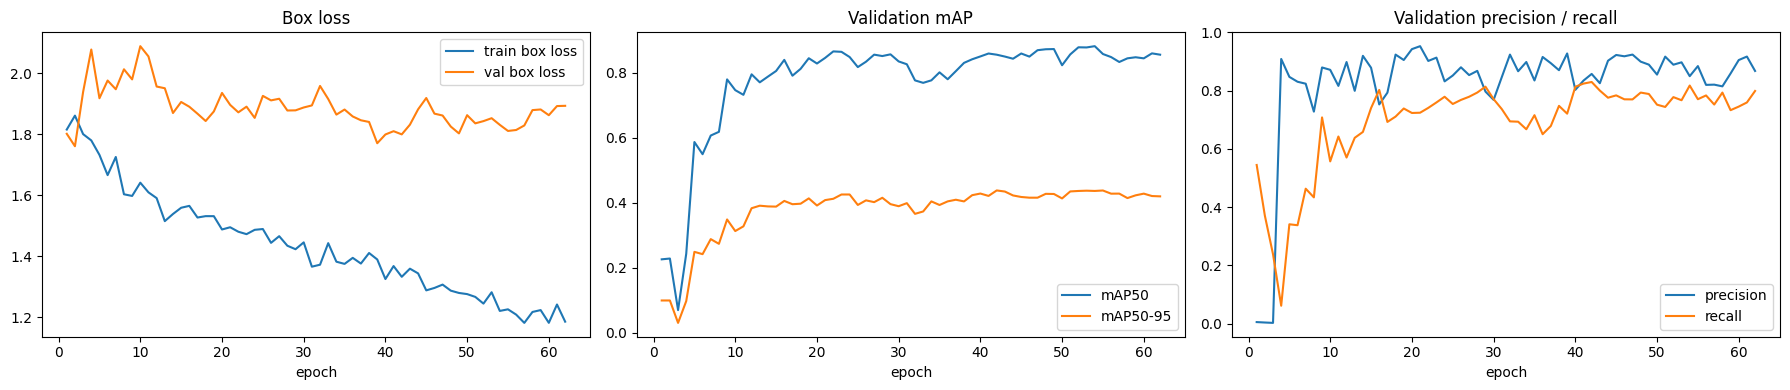

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('/content/runs/detect/yolov8n_baseline/results.csv')
df.columns = df.columns.str.strip()

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].plot(df['epoch'], df['train/box_loss'], label='train box loss')
axes[0].plot(df['epoch'], df['val/box_loss'], label='val box loss')
axes[0].set_title('Box loss'); axes[0].set_xlabel('epoch'); axes[0].legend()

axes[1].plot(df['epoch'], df['metrics/mAP50(B)'], label='mAP50')
axes[1].plot(df['epoch'], df['metrics/mAP50-95(B)'], label='mAP50-95')
axes[1].set_title('Validation mAP'); axes[1].set_xlabel('epoch'); axes[1].legend()

axes[2].plot(df['epoch'], df['metrics/precision(B)'], label='precision')
axes[2].plot(df['epoch'], df['metrics/recall(B)'], label='recall')
axes[2].set_title('Validation precision / recall'); axes[2].set_xlabel('epoch'); axes[2].legend()

plt.tight_layout()
plt.savefig('/content/training_curves.png', dpi=150)
plt.show()


### Task 3 - Comparison architecture - RT-DETR

In [8]:
from ultralytics import RTDETR

comparison = RTDETR('rtdetr-l.pt')

rtdetr_results = comparison.train(
    data='/content/data.yaml',
    epochs=100,
    imgsz=640,
    batch=8,
    patience=20,
    seed=SEED,
    project='/content/runs/detect',
    name='rtdetr_comparison',
    plots=True,
)


Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rtdetr_comparison, nbs=64, nms=None, opset=None, optimize

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      1/100      6.84G       1.78      13.91     0.9661          7        640: 100% ━━━━━━━━━━━━ 16/16 1.5s/it 24.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 4.8s/it 9.6s
                   all         26         83       0.12      0.222      0.127     0.0513

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      2/100      7.23G     0.9847      6.714     0.4431         27        640: 0% ──────────── 0/16  0.5s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      2/100      7.23G     0.7964      3.587     0.3717          7        640: 100% ━━━━━━━━━━━━ 16/16 1.9it/s 8.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.8it/s 0.5s
                   all         26         83      0.461       0.17       0.21     0.0909

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      3/100      7.23G     0.7251      1.056     0.3463         31        640: 0% ──────────── 0/16  0.6s

...

     62/100      7.24G      0.372     0.3702     0.1124         15        640: 100% ━━━━━━━━━━━━ 16/16 1.9it/s 8.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.6it/s 0.6s
                   all         26         83      0.898       0.81      0.806      0.388

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
     63/100      7.24G     0.3704     0.3612    0.08015         33        640: 0% ──────────── 0/16  0.6s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


     63/100      7.24G     0.3643     0.3808     0.1065         14        640: 100% ━━━━━━━━━━━━ 16/16 1.8it/s 8.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.4it/s 0.6s
                   all         26         83      0.909      0.809      0.809      0.391

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
     64/100      7.24G     0.3503      0.353     0.1081         33        640: 0% ──────────── 0/16  0.6s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


     64/100      7.24G     0.3605     0.3801     0.1073         11        640: 100% ━━━━━━━━━━━━ 16/16 1.9it/s 8.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.5it/s 0.6s
                   all         26         83       0.91      0.823      0.815      0.398
EarlyStopping: Training stopped early as no improvement observed in last 20 epochs. Best results observed at epoch 44, best model saved as best.pt.
To update EarlyStopping(patience=20) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.

64 epochs completed in 0.239 hours.
Optimizer stripped from /content/runs/detect/rtdetr_comparison/weights/last.pt, 66.2MB
Optimizer stripped from /content/runs/detect/rtdetr_comparison/weights/best.pt, 66.2MB

Validating /content/runs/detect/rtdetr_comparison/weights/best.pt...
Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
rt-detr-l summary (fused): 

### Task 4 - Quantitative evaluation on the held-out TEST split



In [9]:
baseline_best = YOLO('/content/runs/detect/yolov8n_baseline/weights/best.pt')
metrics_baseline = baseline_best.val(
    data='/content/data.yaml', split='test', plots=True,
    project='/content/runs/detect', name='yolov8n_test_eval'
)

rtdetr_best = RTDETR('/content/runs/detect/rtdetr_comparison/weights/best.pt')
metrics_rtdetr = rtdetr_best.val(
    data='/content/data.yaml', split='test', plots=True,
    project='/content/runs/detect', name='rtdetr_test_eval'
)


Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 74.5±120.4 MB/s, size: 44.3 KB)
val: Scanning /content/data/test/labels... 28 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 28/28 425.6it/s 0.1s
val: New cache created: /content/data/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.5it/s 1.4s
                   all         28         90      0.758      0.687      0.762      0.322
                 cloth         28         28      0.903      0.667      0.878      0.402
                 glove         23         41      0.465      0.537      0.482      0.153
                helmet         21         21      0.906      0.857      0.928       0.41
Speed: 5.1ms preprocess, 10.0ms inference, 0.0ms loss, 2.9ms postprocess per image
Results saved t

###Task 3's quantitative comparison table

In [10]:
def count_params(model):
    return sum(p.numel() for p in model.model.parameters())

comparison_table = pd.DataFrame({
    'Model': ['YOLOv8n (baseline)', 'RT-DETR-l (comparison)'],
    'Params (M)': [count_params(baseline_best) / 1e6, count_params(rtdetr_best) / 1e6],
    'mAP50 (test)': [metrics_baseline.box.map50, metrics_rtdetr.box.map50],
    'mAP50-95 (test)': [metrics_baseline.box.map, metrics_rtdetr.box.map],
    'Precision (test)': [metrics_baseline.box.mp, metrics_rtdetr.box.mp],
    'Recall (test)': [metrics_baseline.box.mr, metrics_rtdetr.box.mr],
    'Inference (ms/img)': [metrics_baseline.speed['inference'], metrics_rtdetr.speed['inference']],
})
comparison_table['FPS'] = 1000 / comparison_table['Inference (ms/img)']
comparison_table


,Model,Params (M),mAP50 (test),mAP50-95 (test),Precision (test),Recall (test),Inference (ms/img),FPS
0,YOLOv8n (baseline),3.011433,0.762440,0.321637,0.758083,0.686761,10.045699,99.545091
1,RT-DETR-l (comparison),32.812241,0.803665,0.341909,0.936465,0.789641,51.832658,19.292856


###Task 4 - Effect of confidence and IoU thresholds

In [11]:
conf_sensitivity = []
for conf in [0.10, 0.25, 0.50, 0.70]:
    m = baseline_best.val(data='/content/data.yaml', split='test', conf=conf, iou=0.5,
                           plots=False, verbose=False)
    conf_sensitivity.append({'conf_threshold': conf, 'precision': m.box.mp,
                              'recall': m.box.mr, 'mAP50': m.box.map50})

conf_df = pd.DataFrame(conf_sensitivity)
print('Effect of confidence threshold (IoU fixed at 0.5):')
display(conf_df)

iou_sensitivity = []
for iou in [0.3, 0.5, 0.7, 0.9]:
    m = baseline_best.val(data='/content/data.yaml', split='test', conf=0.25, iou=iou,
                           plots=False, verbose=False)
    iou_sensitivity.append({'iou_threshold': iou, 'precision': m.box.mp,
                             'recall': m.box.mr, 'mAP50': m.box.map50})

iou_df = pd.DataFrame(iou_sensitivity)
print('Effect of IoU threshold (confidence fixed at 0.25):')
display(iou_df)


Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1578.4±502.2 MB/s, size: 53.9 KB)
val: Scanning /content/data/test/labels.cache... 28 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 28/28 8.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.2it/s 0.9s
                   all         28         90       0.82      0.727      0.684      0.287
Speed: 2.0ms preprocess, 5.7ms inference, 0.0ms loss, 3.8ms postprocess per image
Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1275.0±435.5 MB/s, size: 44.4 KB)
val: Scanning /content/data/test/labels.cache... 28 images, 0 backgrounds, 0 corrupt

,conf_threshold,precision,recall,mAP50
0,0.10,0.820226,0.727062,0.683527
1,0.25,0.906667,0.634437,0.608124
2,0.50,0.944444,0.562427,0.543730
3,0.70,0.916667,0.369628,0.367500


Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1659.9±579.9 MB/s, size: 53.4 KB)
val: Scanning /content/data/test/labels.cache... 28 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 28/28 9.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.3it/s 0.6s
                   all         28         90      0.924      0.626      0.604      0.253
Speed: 1.7ms preprocess, 4.7ms inference, 0.0ms loss, 1.3ms postprocess per image
Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1771.5±558.4 MB/s, size: 49.2 KB)
val: Scanning /content/data/test/labels.cache... 28 images, 0 backgrounds, 0 corrupt

,iou_threshold,precision,recall,mAP50
0,0.3,0.924242,0.626307,0.603548
1,0.5,0.906667,0.634437,0.608124
2,0.7,0.820551,0.634437,0.604535
3,0.9,0.650138,0.562427,0.542038


### 7. Qualitative error analysis


In [12]:
baseline_best.predict(source='/content/data/test/images', save=True, conf=0.25,
                      project='/content/runs/detect', name='qual_test_preds')

baseline_best.predict(source='/content/unseen_demo/test', save=True, conf=0.25,
                       project='/content/runs/detect', name='qual_unseen_preds')

import glob
from IPython.display import Image, display

print('Predictions on the held-out TEST split (has ground truth to compare against):')
for p in sorted(glob.glob('/content/runs/detect/qual_test_preds/*.jpg')):
    display(Image(filename=p, width=420))

print('Predictions on the unlabeled unseen images (no ground truth — visual check only):')
for p in sorted(glob.glob('/content/runs/detect/qual_unseen_preds/*.jpg')):
    display(Image(filename=p, width=420))


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

### Save trained models and results for submission



In [13]:
!mkdir -p /content/my_model
!cp /content/runs/detect/yolov8n_baseline/weights/best.pt /content/my_model/yolov8n_best.pt
!cp /content/runs/detect/rtdetr_comparison/weights/best.pt /content/my_model/rtdetr_best.pt
!cp -r /content/runs/detect /content/my_model/runs
!cp /content/data.yaml /content/my_model/data.yaml

%cd /content/my_model
!zip -rq /content/my_model.zip .
%cd /content

from google.colab import files
files.download('/content/my_model.zip')


/content/my_model
/content


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>